[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch03_Lab01_2026_stepwise.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 3: One Neuron** (Part I: The Learning Machine). Also used in Chapter 2.

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=3](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=3)
* The video course this book grew from: [www.aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# Lab 01 — Is this digit a 3?
## Learning Neural Network Basics with MNIST

In this lab we build the **simplest possible neural network**: 784 inputs → 1 output.
Its only job is to answer one question about a handwritten digit image: *"Is this a 3?"*

**Learning objectives**

1. Understand inputs and outputs in neural networks
2. Learn about weights and biases
3. Understand the sigmoid activation function
4. Implement binary classification
5. See how a neural network learns through training

**How to use this notebook:** run the cells one at a time, top to bottom (`Shift + Enter`).
Read the text above each cell first, then look at what the cell prints or plots.
Cells depend on the ones before them, so don't skip any.

> ### ✅ Checked edition (November 2026)
> This notebook was re-run top to bottom and checked for *The Why Book of Deep Learning, Part 1*. What changed from the original:
>
> * **Fixed a syntax error in Step 12** (the training cell): the line `y_train_binary,` had been replaced by a stray `\`, so the notebook stopped there and never trained.
> * **Colours now match the text.** `cmap='RdBu'` draws *negative* values red; the text said red = positive. The weight pictures now use `RdBu_r`, so red really is positive.
> * The model starts with `keras.Input(shape=(784,))` instead of the deprecated `input_shape=` argument.
> * Step 16 now prints the "always say not-3" yardstick next to the test accuracy, so the score can be judged honestly.
> * The file now has the `.ipynb` extension, so it opens directly.

---
## Step 1 — Import the libraries

Four tools do all the work in this lab:

| Library | What we use it for |
|---|---|
| `numpy` | fast maths on arrays of numbers |
| `matplotlib.pyplot` | drawing images and graphs |
| `keras` | building and training the neural network |
| `keras.layers` | the building blocks (we use just one: `Dense`) |

In [1]:
# Step 1: Import Required Libraries
# =================================
import numpy as np              # For numerical operations
import matplotlib.pyplot as plt # For plotting and visualization
import keras                    # Deep learning framework
from keras import layers       # Neural network layers

print("✅ Libraries imported successfully!")
print(f"Using Keras version: {keras.__version__}")

✅ Libraries imported successfully!
Using Keras version: 3.14.1


---
## Step 2 — Load and explore the MNIST dataset

MNIST is a classic dataset of **70,000 handwritten digits**, already split for us:

- **60,000 training images** — the network learns from these
- **10,000 test images** — kept aside to check whether it really learned

Each image is **28 × 28 = 784 pixels**, and each pixel is a number from **0** (black) to **255** (white).
The *label* is the digit the image shows (0–9).

> **Look for:** the shape `(60000, 28, 28)` means "60,000 images, each 28 rows by 28 columns".

In [2]:
# Step 2: Load and Explore the MNIST Dataset
# ==========================================
print("\n🔍 Loading MNIST dataset...")

# The MNIST dataset contains 70,000 images of handwritten digits (0-9)
# Each image is 28x28 pixels (784 total pixels)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print(f"Training images shape: {x_train.shape}")  # (60000, 28, 28)
print(f"Training labels shape: {y_train.shape}")  # (60000,)
print(f"Test images shape: {x_test.shape}")       # (10000, 28, 28)
print(f"Test labels shape: {y_test.shape}")       # (10000,)

# Let's look at what the data contains
print(f"\nPixel values range from {x_train.min()} to {x_train.max()}")
print(f"Unique digit labels: {np.unique(y_train)}")


🔍 Loading MNIST dataset...


Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Test images shape: (10000, 28, 28)
Test labels shape: (10000,)

Pixel values range from 0 to 255
Unique digit labels: [0 1 2 3 4 5 6 7 8 9]


---
## Step 3 — Visualise some sample images

Before touching any maths, always *look* at your data.
This cell picks 10 random training images and shows them with their labels.

> **Try it:** run this cell a few times — you get different random digits each run.
> Notice how differently people write the same digit.


📊 Visualizing sample digits...


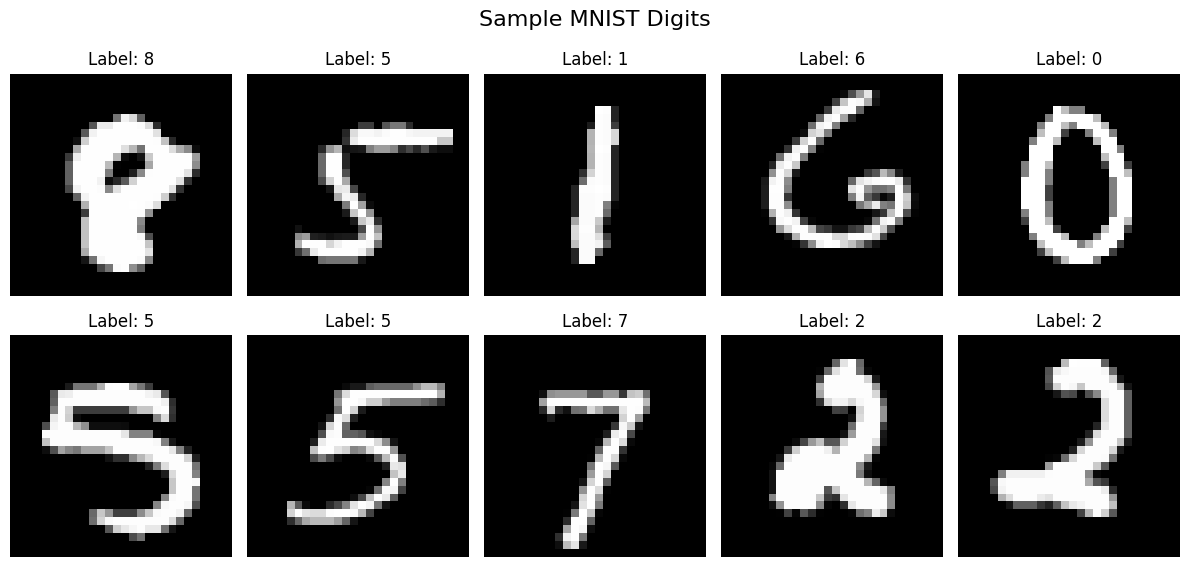

In [3]:
# Step 3: Visualize Some Sample Images
# ===================================
print("\n📊 Visualizing sample digits...")

# Create a figure to show some example images
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
fig.suptitle('Sample MNIST Digits', fontsize=16)

# Show 10 random samples
for i in range(10):
    row = i // 5
    col = i % 5

    # Pick a random image
    idx = np.random.randint(0, len(x_train))
    image = x_train[idx]
    label = y_train[idx]

    # Display the image
    axes[row, col].imshow(image, cmap='gray')
    axes[row, col].set_title(f'Label: {label}')
    axes[row, col].axis('off')

plt.tight_layout()
plt.show()

---
## Step 4 — Turn this into a binary classification problem

MNIST has 10 classes (0–9), but we want one simple question: **"Is it a 3?"**

So we rewrite every label:

- label is `3` → new label **1** (yes)
- anything else → new label **0** (no)

`(y_train == 3)` gives an array of `True`/`False`, and `.astype(int)` turns those into `1`/`0`.

> **Look for:** the classes are *imbalanced* — only about 1 in 10 images is a 3.
> That means a lazy model that always guesses "not 3" would already be ~90% accurate.
> Keep that in mind when we judge our accuracy later!

In [4]:
# Step 4: Convert to Binary Classification Problem
# ===============================================
print("\n🔄 Converting to binary classification...")

# We want to classify: "Is this digit a 3?" (Yes=1, No=0)
# This transforms our 10-class problem into a binary problem

# Convert labels to binary: 1 if digit is 3, 0 otherwise
y_train_binary = (y_train == 3).astype(int)  # True becomes 1, False becomes 0
y_test_binary = (y_test == 3).astype(int)

print(f"Original label example: {y_train[:10]}")
print(f"Binary label example:   {y_train_binary[:10]}")
print(f"\nClass distribution:")
print(f"  Not digit 3 (class 0): {np.sum(y_train_binary == 0)} images")
print(f"  Is digit 3 (class 1):  {np.sum(y_train_binary == 1)} images")


🔄 Converting to binary classification...
Original label example: [5 0 4 1 9 2 1 3 1 4]
Binary label example:   [0 0 0 0 0 0 0 1 0 0]

Class distribution:
  Not digit 3 (class 0): 53869 images
  Is digit 3 (class 1):  6131 images


---
## Step 5 — Preprocess the input data

Two changes are needed before the pixels can go into the network:

1. **Flatten** — the network takes a flat list of numbers, not a 2D grid.
   So `28 × 28` becomes one long vector of `784` values.
2. **Normalise** — divide by 255 so every pixel is between `0.0` and `1.0`.
   Neural networks train much more reliably on small, similarly-sized inputs.

In [5]:
# Step 5: Preprocess the Input Data
# =================================
print("\n⚙️ Preprocessing the input data...")

# IMPORTANT CONCEPT: Neural networks work best with normalized inputs
# Current pixel values: 0-255 (integers)
# We'll convert to: 0.0-1.0 (floating point)

# Flatten images from 28x28 to 784-dimensional vectors
# This creates our INPUT FEATURES for the neural network
x_train_processed = x_train.reshape(x_train.shape[0], 784).astype('float32') / 255.0
x_test_processed = x_test.reshape(x_test.shape[0], 784).astype('float32') / 255.0

print(f"Original image shape: {x_train[0].shape}")  # (28, 28)
print(f"Flattened shape: {x_train_processed[0].shape}")  # (784,)
print(f"Pixel value range after normalization: {x_train_processed.min():.1f} to {x_train_processed.max():.1f}")


⚙️ Preprocessing the input data...
Original image shape: (28, 28)
Flattened shape: (784,)
Pixel value range after normalization: 0.0 to 1.0


### What does "flattening" actually look like?

The left picture is the digit as we see it. The right strip is the *exact same numbers*,
laid out end to end in a single row of 784 values — that is what the network receives.

> **Key idea:** the network has no notion of "next to" or "above". It only sees 784 numbers
> in a fixed order. Any structure it learns has to come from the training data.


🔍 Understanding image flattening:


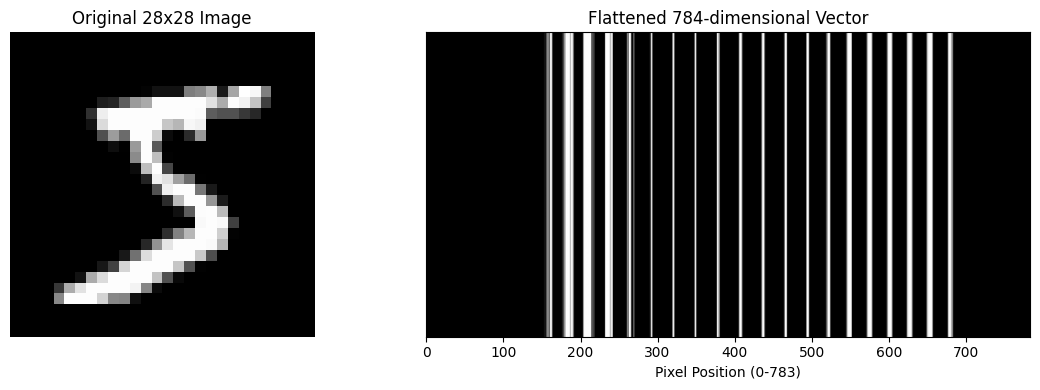

In [6]:
# Visualize what flattening means
print("\n🔍 Understanding image flattening:")
sample_image = x_train[0]
sample_flattened = x_train_processed[0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Original 2D image
ax1.imshow(sample_image, cmap='gray')
ax1.set_title('Original 28x28 Image')
ax1.axis('off')

# Flattened 1D representation (shown as a heatmap)
ax2.imshow(sample_flattened.reshape(1, 784), cmap='gray', aspect='auto')
ax2.set_title('Flattened 784-dimensional Vector')
ax2.set_xlabel('Pixel Position (0-783)')
ax2.set_ylabel('')
ax2.set_yticks([])

plt.tight_layout()
plt.show()

---
## Step 6 — Build the neural network

Our architecture is as small as it gets:

```
784 inputs  ──(784 weights + 1 bias)──►  1 neuron  ──sigmoid──►  probability of "is a 3"
```

- **No hidden layers.** The pixels connect straight to the output.
- **Weights:** one per pixel — `784`. Each weight says how much that pixel votes for/against "3".
- **Bias:** `1` extra number that shifts the answer up or down regardless of the input.
- **Total parameters:** `784 + 1 = 785`.
- **Sigmoid activation:** squashes any number into the range `(0, 1)` so we can read it as a probability.

In [7]:
# Step 6: Build Our Neural Network Model (Simplified)
# ===================================================
print("\n🧠 Building the neural network...")

# SIMPLIFIED NEURAL NETWORK ARCHITECTURE:
# Input Layer:  784 neurons (one for each pixel)
# Output Layer: 1 neuron with sigmoid activation (for binary classification)
#
# This is the SIMPLEST possible neural network for this task!
# No hidden layers - direct connection from inputs to output

model = keras.Sequential([
    keras.Input(shape=(784,)),   # 784 input features (one per pixel)
    # Single Dense Layer: Direct connection from 784 inputs to 1 output
    # WEIGHTS: 784 inputs × 1 neuron = 784 weights
    # BIASES: 1 bias
    # ACTIVATION: Sigmoid - squashes output to range (0,1), interpretable as probability
    layers.Dense(1,
                activation='sigmoid',   # Sigmoid activation for binary classification
                name='output_layer')
])

# Display model architecture
print("🏗️ Simplified Model Architecture:")
model.summary()
print(f"\nThis simple model has only {model.count_params():,} parameters!")
print("Each of the 784 pixels has its own weight, plus 1 bias term.")


🧠 Building the neural network...
🏗️ Simplified Model Architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ output_layer (Dense)            │ (None, 1)              │           785 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 785 (3.07 KB)

 Trainable params: 785 (3.07 KB)

 Non-trainable params: 0 (0.00 B)


This simple model has only 785 parameters!
Each of the 784 pixels has its own weight, plus 1 bias term.


---
## Step 7 — Inspect the weights and biases *before* training

Keras has already filled the weights with **small random numbers** and set the bias to `0`.
The network currently knows nothing. Let's look at those starting values.

`get_weights()` returns two arrays: the weight matrix `(784, 1)` and the bias `(1,)`.

In [8]:
# Step 7: Understanding Weights and Biases (Before Training)
# =========================================================
print("\n⚖️ Understanding Weights and Biases (Before Training)...")

# Let's examine the initial weights (before training)
initial_weights, initial_biases = model.layers[0].get_weights()

print(f"Layer weights shape: {initial_weights.shape}")  # (784, 1)
print(f"Layer biases shape: {initial_biases.shape}")    # (1,)
print(f"Initial bias value: {initial_biases[0]:.6f}")

print(f"\nTotal trainable parameters: {model.count_params():,}")
print(f"  - Weights: {initial_weights.size:,} (one per pixel)")
print(f"  - Biases: {initial_biases.size:,} (one for the output)")


⚖️ Understanding Weights and Biases (Before Training)...
Layer weights shape: (784, 1)
Layer biases shape: (1,)
Initial bias value: 0.000000

Total trainable parameters: 785
  - Weights: 784 (one per pixel)
  - Biases: 1 (one for the output)


### Picture the untrained weights

Because there is exactly one weight per pixel, we can reshape the 784 weights back into a
28 × 28 image and *see* them. Red = positive weight, blue = negative (the colour map is `RdBu_r`; plain `RdBu` would show the opposite).

> **Look for:** pure random noise, no pattern at all. Come back and compare this with Step 13.
> (The bottom row of the figure is a placeholder we fill in mentally after training.)

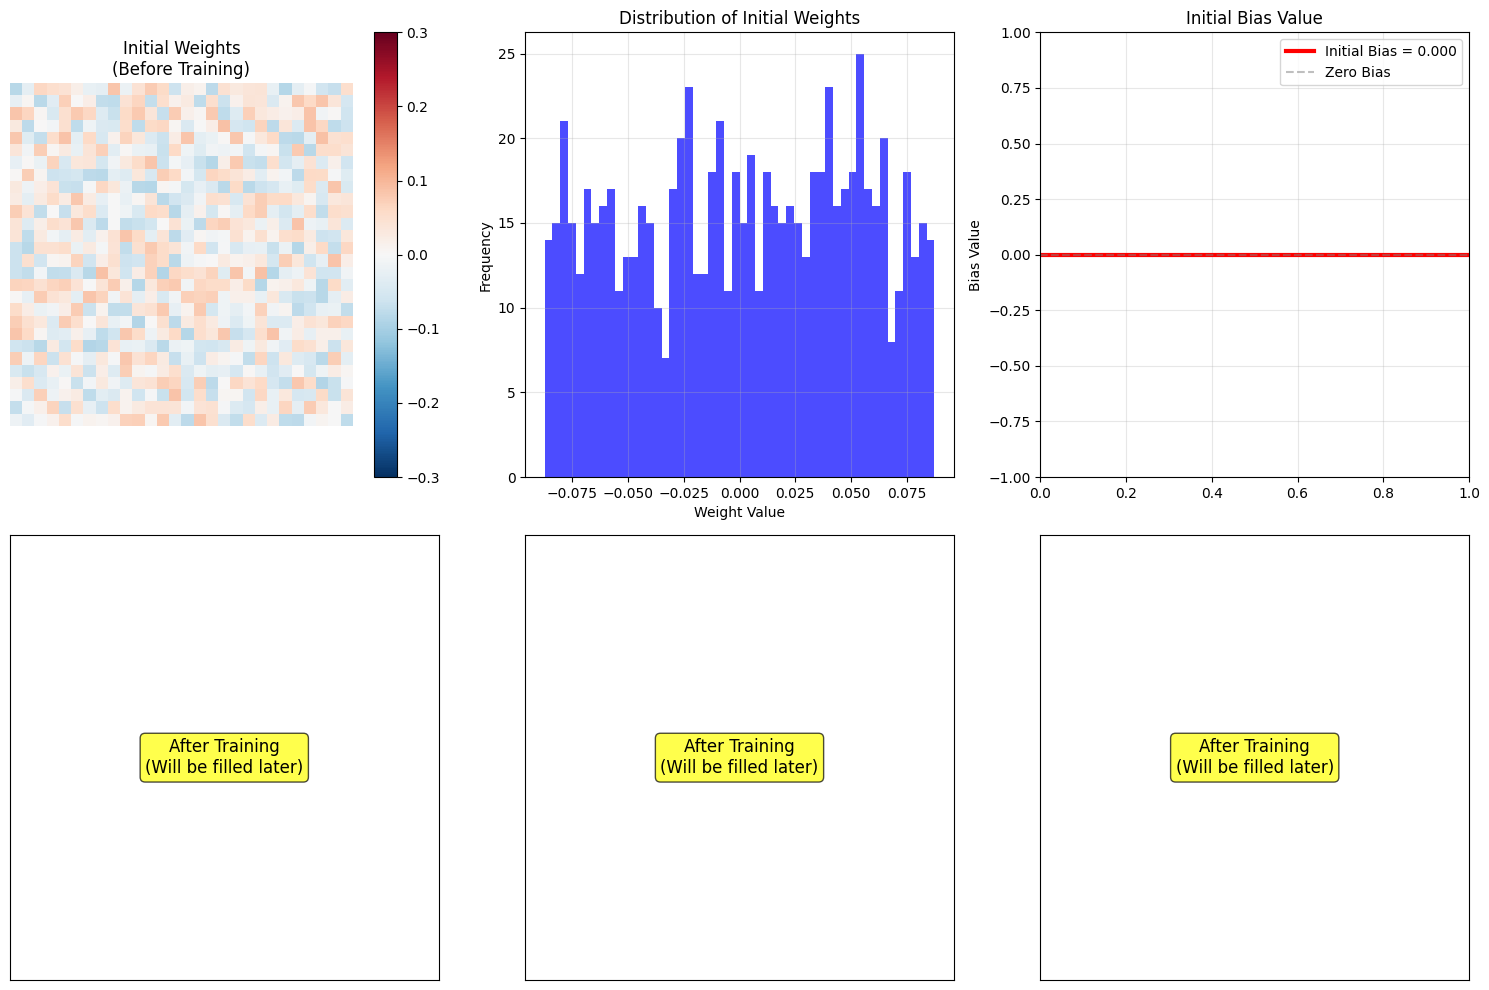

In [9]:
# Visualize initial weights as an image
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Show initial weights as image
weights_image = initial_weights.reshape(28, 28)
im1 = axes[0, 0].imshow(weights_image, cmap='RdBu_r', vmin=-0.3, vmax=0.3)
axes[0, 0].set_title('Initial Weights\n(Before Training)')
axes[0, 0].axis('off')
plt.colorbar(im1, ax=axes[0, 0])

# Show distribution of initial weights
axes[0, 1].hist(initial_weights.flatten(), bins=50, alpha=0.7, color='blue')
axes[0, 1].set_title('Distribution of Initial Weights')
axes[0, 1].set_xlabel('Weight Value')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].grid(True, alpha=0.3)

# Show effect of bias
axes[0, 2].axhline(y=initial_biases[0], color='red', linewidth=3, label=f'Initial Bias = {initial_biases[0]:.3f}')
axes[0, 2].axhline(y=0, color='gray', linestyle='--', alpha=0.5, label='Zero Bias')
axes[0, 2].set_ylim(-1, 1)
axes[0, 2].set_title('Initial Bias Value')
axes[0, 2].set_ylabel('Bias Value')
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3)

# We'll fill the bottom row after training
for i in range(3):
    axes[1, i].text(0.5, 0.5, 'After Training\n(Will be filled later)',
                    ha='center', va='center', transform=axes[1, i].transAxes,
                    fontsize=12, bbox=dict(boxstyle="round,pad=0.3", facecolor="yellow", alpha=0.7))
    axes[1, i].set_xticks([])
    axes[1, i].set_yticks([])

plt.tight_layout()
plt.show()

---
## Step 8 — Compile the model, then predict *before* training

**Compiling** tells Keras three things:

- **Optimizer `adam`** — the algorithm that adjusts the weights during training.
- **Loss `binary_crossentropy`** — the score that measures how wrong a probability is.
  Standard choice for yes/no problems.
- **Metric `accuracy`** — the human-friendly number we watch (fraction of correct answers).

Compiling does **not** train anything; it just sets up the rules.

In [10]:
print("\n🎲 Testing predictions BEFORE training...")
print("Let's see what the untrained network predicts (should be random!)")

# Compile model first (needed for predictions)
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)


🎲 Testing predictions BEFORE training...
Let's see what the untrained network predicts (should be random!)


### What does an untrained network predict?

We take 1,000 random test images and ask the untrained network. Since the weights are random,
its answers should be essentially meaningless.

> **Look for:** the accuracy will be some arbitrary number, and every prediction sits near 0.5
> ("no idea"). This is our **baseline** — training has to beat it.

In [11]:
# Make predictions on a small subset before training
test_sample_size = 1000
sample_indices = np.random.choice(len(x_test_processed), test_sample_size, replace=False)
x_sample = x_test_processed[sample_indices]
y_sample = y_test_binary[sample_indices]

# Get predictions before training
print("Making predictions with untrained network...")
predictions_before = model.predict(x_sample, verbose=0)

# Evaluate accuracy before training
predicted_classes_before = (predictions_before > 0.5).astype(int)
accuracy_before = np.mean(predicted_classes_before.flatten() == y_sample)

print(f"Accuracy BEFORE training: {accuracy_before:.4f} ({accuracy_before*100:.2f}%)")
print(f"Random guessing would be ~50%, we got: {accuracy_before*100:.1f}%")
print(f"Prediction distribution: {np.mean(predictions_before):.3f} ± {np.std(predictions_before):.3f}")

Making predictions with untrained network...
Accuracy BEFORE training: 0.3230 (32.30%)
Random guessing would be ~50%, we got: 32.3%
Prediction distribution: 0.547 ± 0.094


---
## Step 9 — Trace the maths by hand

A neuron does exactly two things:

$$ z = \sum_{i=1}^{784} (\text{pixel}_i \times \text{weight}_i) + \text{bias} \qquad\text{then}\qquad \hat{y} = \sigma(z) = \frac{1}{1+e^{-z}} $$

- `z` is the **pre-activation** (or "raw output") — any real number.
- `ŷ` is the **post-activation** — always between 0 and 1, read as a probability.

Below we compute this ourselves with `np.dot` for 5 images, instead of letting Keras do it.

In [12]:
# Step 9: Understanding Sigmoid and Pre-Activation Values
# ======================================================
print("\n📈 Understanding Sigmoid and Pre-Activation Values...")

# Let's manually compute what happens inside the network for a few samples
sample_images = x_sample[:5]
print("Tracing computation for 5 sample images:")

# Manual forward pass to see pre-sigmoid values
pre_sigmoid_values = []
post_sigmoid_values = []

# Define sigmoid function here if not already defined globally or imported
def sigmoid(x):
    """Sigmoid activation function"""
    return 1 / (1 + np.exp(-np.clip(x, -250, 250)))  # Clip to avoid overflow

for i, image in enumerate(sample_images):
    # Compute pre-sigmoid value (raw output before activation)
    raw_output = np.dot(image, initial_weights.flatten()) + initial_biases[0]
    sigmoid_output = sigmoid(raw_output)

    pre_sigmoid_values.append(raw_output)
    post_sigmoid_values.append(sigmoid_output)

    actual_label = y_sample[i]
    print(f"Sample {i+1}: Pre-sigmoid={raw_output:6.3f} → Post-sigmoid={sigmoid_output:.3f} | Actual: {actual_label}")


📈 Understanding Sigmoid and Pre-Activation Values...
Tracing computation for 5 sample images:
Sample 1: Pre-sigmoid= 0.361 → Post-sigmoid=0.589 | Actual: 0
Sample 2: Pre-sigmoid=-0.098 → Post-sigmoid=0.476 | Actual: 0
Sample 3: Pre-sigmoid= 0.354 → Post-sigmoid=0.588 | Actual: 0
Sample 4: Pre-sigmoid=-0.282 → Post-sigmoid=0.430 | Actual: 0
Sample 5: Pre-sigmoid= 0.299 → Post-sigmoid=0.574 | Actual: 0


### Visualise those five samples and the sigmoid curve

The last panel plots each sample's pre-sigmoid value against its post-sigmoid value,
with the sigmoid curve drawn through them.

> **Look for:** all five points are bunched near the middle of the curve, i.e. near probability 0.5.
> An untrained network is not confident about anything.

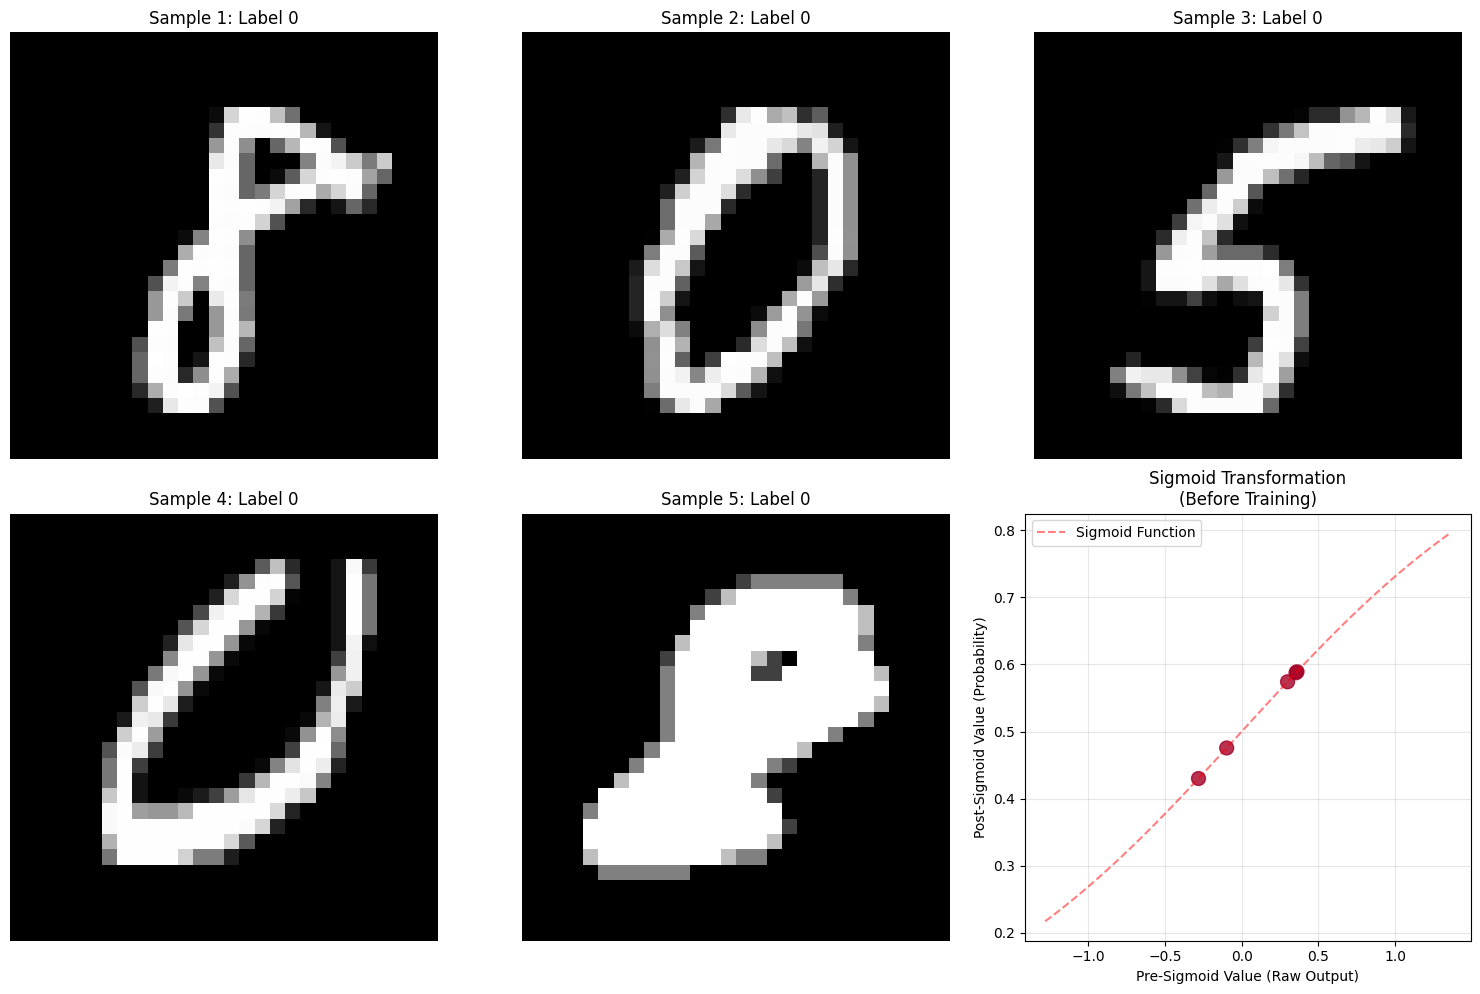

In [13]:
# Visualize the transformation
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Show the sample images
for i in range(5):
    row = 0
    col = i if i < 3 else i - 3
    if i >= 3:
        row = 1
    axes[row, col].imshow(sample_images[i].reshape(28, 28), cmap='gray')
    axes[row, col].set_title(f'Sample {i+1}: Label {y_sample[i]}')
    axes[row, col].axis('off')

# Plot pre-sigmoid vs post-sigmoid values
axes[1, 2].scatter(pre_sigmoid_values, post_sigmoid_values, c=y_sample[:5],
                   cmap='RdYlBu', s=100, alpha=0.8)
axes[1, 2].set_xlabel('Pre-Sigmoid Value (Raw Output)')
axes[1, 2].set_ylabel('Post-Sigmoid Value (Probability)')
axes[1, 2].set_title('Sigmoid Transformation\n(Before Training)')
axes[1, 2].grid(True, alpha=0.3)

# Add sigmoid curve for reference
x_range = np.linspace(min(pre_sigmoid_values)-1, max(pre_sigmoid_values)+1, 100)
y_sigmoid = sigmoid(x_range)
axes[1, 2].plot(x_range, y_sigmoid, 'r--', alpha=0.5, label='Sigmoid Function')
axes[1, 2].legend()

plt.tight_layout()
plt.show()

### The role of the bias

The weights decide *how the input matters*. The bias decides the **default answer** when the
weighted sum is zero — it slides the whole decision boundary left or right.

- bias = 0 → σ(0) = 0.5, perfectly undecided
- bias > 0 → leans towards "is a 3"
- bias < 0 → leans towards "not a 3"


🔍 Understanding the role of BIAS:
Initial bias value: 0.000000
This bias shifts ALL predictions by the same amount
If bias = 0: sigmoid(0) = 0.5 (neutral)
If bias > 0: sigmoid(positive) > 0.5 (favors class 1)
If bias < 0: sigmoid(negative) < 0.5 (favors class 0)


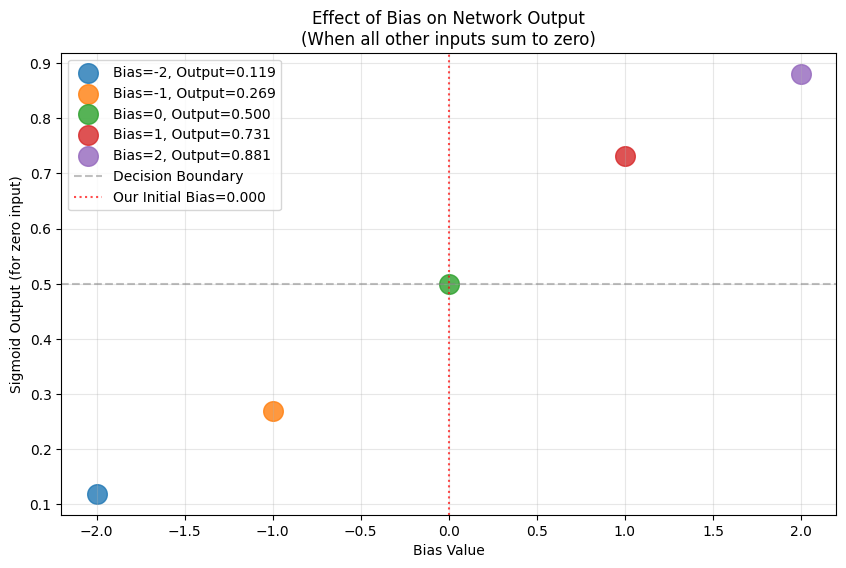

In [14]:
# Analyze the effect of bias
print(f"\n🔍 Understanding the role of BIAS:")
print(f"Initial bias value: {initial_biases[0]:.6f}")
print(f"This bias shifts ALL predictions by the same amount")
print(f"If bias = 0: sigmoid(0) = 0.5 (neutral)")
print(f"If bias > 0: sigmoid(positive) > 0.5 (favors class 1)")
print(f"If bias < 0: sigmoid(negative) < 0.5 (favors class 0)")

# Show effect of different bias values
bias_demo_values = np.array([-2, -1, 0, 1, 2])
fig, ax = plt.subplots(1, 1, figsize=(10, 6))

for bias_val in bias_demo_values:
    # Assume zero input (average case)
    zero_input_output = sigmoid(0 + bias_val)
    ax.scatter(bias_val, zero_input_output, s=200, alpha=0.8,
               label=f'Bias={bias_val}, Output={zero_input_output:.3f}')

ax.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='Decision Boundary')
ax.axvline(x=initial_biases[0], color='red', linestyle=':', alpha=0.7,
           label=f'Our Initial Bias={initial_biases[0]:.3f}')
ax.set_xlabel('Bias Value')
ax.set_ylabel('Sigmoid Output (for zero input)')
ax.set_title('Effect of Bias on Network Output\n(When all other inputs sum to zero)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

---
## Step 10 — The sigmoid function in full

$$\sigma(x) = \frac{1}{1 + e^{-x}}$$

Three properties make it the right choice for the output of a binary classifier:

1. **Bounded** — output always lands in `(0, 1)`, so it reads as a probability.
2. **Smooth** — it has a well-behaved derivative everywhere, which is what training needs.
3. **Centred at 0.5** — `σ(0) = 0.5`, giving us a natural decision threshold.

We classify as "is a 3" when the output is **above 0.5**, and "not a 3" otherwise.


📈 Understanding the Sigmoid Activation Function...


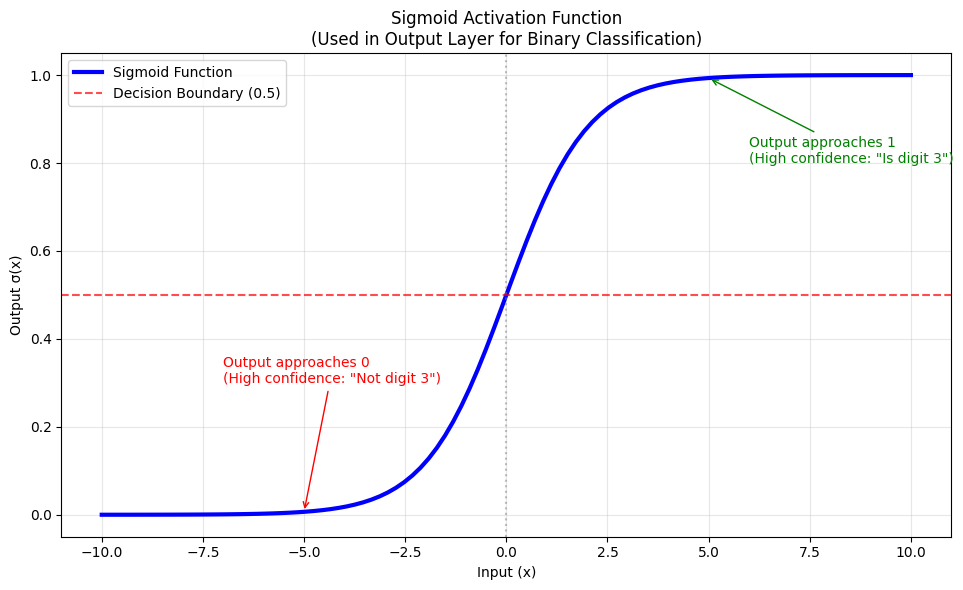

In [15]:
# Step 10: Understanding the Sigmoid Function
# ==========================================
print("\n📈 Understanding the Sigmoid Activation Function...")

# The sigmoid function maps any real number to a value between 0 and 1
# Formula: σ(x) = 1 / (1 + e^(-x))
# This is perfect for binary classification (probability of being class 1)

# Create a range of inputs to plot
x_values = np.linspace(-10, 10, 100)
y_values = sigmoid(x_values)

plt.figure(figsize=(10, 6))
plt.plot(x_values, y_values, 'b-', linewidth=3, label='Sigmoid Function')
plt.axhline(y=0.5, color='r', linestyle='--', alpha=0.7, label='Decision Boundary (0.5)')
plt.axvline(x=0, color='gray', linestyle=':', alpha=0.5)
plt.xlabel('Input (x)')
plt.ylabel('Output σ(x)')
plt.title('Sigmoid Activation Function\n(Used in Output Layer for Binary Classification)')
plt.grid(True, alpha=0.3)
plt.legend()

# Add annotations
plt.annotate('Output approaches 1\n(High confidence: "Is digit 3")',
             xy=(5, sigmoid(5)), xytext=(6, 0.8),
             arrowprops=dict(arrowstyle='->', color='green'),
             fontsize=10, color='green')

plt.annotate('Output approaches 0\n(High confidence: "Not digit 3")',
             xy=(-5, sigmoid(-5)), xytext=(-7, 0.3),
             arrowprops=dict(arrowstyle='->', color='red'),
             fontsize=10, color='red')

plt.tight_layout()
plt.show()

---
## Step 11 — Compilation recap

Nothing new runs here — the model was compiled in Step 8. This cell just restates the settings
so they're in one place.

In [16]:
# Step 11: Compile the Model
# ========================
print("\n🔧 Model already compiled in previous step!")
print("✅ Model compilation settings:")
print(f"  Optimizer: Adam (adaptive learning rate)")
print(f"  Loss Function: Binary Crossentropy")
print(f"  Metrics: Accuracy")


🔧 Model already compiled in previous step!
✅ Model compilation settings:
  Optimizer: Adam (adaptive learning rate)
  Loss Function: Binary Crossentropy
  Metrics: Accuracy


---
## Step 12 — Train the model

Now the learning happens. For each batch of 32 images the network:

1. predicts,
2. measures the loss (how wrong it was),
3. nudges all 785 parameters slightly in the direction that reduces that loss.

Key arguments:

- `epochs=10` — go through the whole training set 10 times.
- `batch_size=32` — update the weights after every 32 images.
- `validation_split=0.2` — hold back 20% of the training data to check for overfitting.

> **Look for:** `loss` should fall and `accuracy` should rise each epoch. Watch `val_accuracy`
> too — if training accuracy keeps climbing while validation accuracy stalls, the model is
> memorising rather than learning.

*(This takes roughly a minute. The output is long — that's normal.)*

In [17]:
# Step 12: Train the Model
# =======================
print("\n🚀 Training the neural network...")
print("This is where the magic happens - the model learns to recognize digit 3!")

# Training will show how loss decreases and accuracy improves over time
print("\nTraining Progress:")
print("- Loss should decrease (model makes fewer errors)")
print("- Accuracy should increase (model gets better at classification)")

# Train for more epochs since we have a simpler model
history = model.fit(
    x_train_processed,           # Input: flattened, normalized images
    y_train_binary,              # Target: 1 if the digit is a 3, else 0
    epochs=10,                   # More epochs for the simpler model
    batch_size=32,               # Process 32 samples at a time
    validation_split=0.2,        # Use 20% of training data for validation
    verbose=1                    # Show progress
)

print("\n✅ Training completed!")


🚀 Training the neural network...
This is where the magic happens - the model learns to recognize digit 3!

Training Progress:
- Loss should decrease (model makes fewer errors)
- Accuracy should increase (model gets better at classification)
Epoch 1/10


   1/1500 ━━━━━━━━━━━━━━━━━━━━ 8:17 332ms/step - accuracy: 0.3750 - loss: 0.7498

  55/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 928us/step - accuracy: 0.7494 - loss: 0.5374  

 114/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 894us/step - accuracy: 0.8075 - loss: 0.4664

 177/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 862us/step - accuracy: 0.8336 - loss: 0.4216

 238/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 852us/step - accuracy: 0.8494 - loss: 0.3906

... (253 outputs left out)

1390/1500 ━━━━━━━━━━━━━━━━━━━━ 0s 798us/step - accuracy: 0.9754 - loss: 0.0833

1453/1500 ━━━━━━━━━━━━━━━━━━━━ 0s 798us/step - accuracy: 0.9753 - loss: 0.0833

1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9750 - loss: 0.0834 - val_accuracy: 0.9766 - val_loss: 0.0770



✅ Training completed!


---
## Step 13 — Compare before and after training

Same network, same 1,000 test images — but the parameters have changed. Let's measure the difference.

In [18]:
# Step 13: Compare Before and After Training
# ==========================================
print("\n🔄 Comparing Before and After Training...")

# Get trained weights and biases
trained_weights, trained_biases = model.layers[0].get_weights()

print(f"Bias change: {initial_biases[0]:.6f} → {trained_biases[0]:.6f}")
print(f"Bias shift: {trained_biases[0] - initial_biases[0]:+.6f}")

# Test predictions after training
predictions_after = model.predict(x_sample, verbose=0)
predicted_classes_after = (predictions_after > 0.5).astype(int)
accuracy_after = np.mean(predicted_classes_after.flatten() == y_sample)

print(f"\nAccuracy comparison:")
print(f"  Before training: {accuracy_before:.4f} ({accuracy_before*100:.2f}%)")
print(f"  After training:  {accuracy_after:.4f} ({accuracy_after*100:.2f}%)")
print(f"  Improvement: +{(accuracy_after-accuracy_before)*100:.2f} percentage points")


🔄 Comparing Before and After Training...
Bias change: 0.000000 → -2.065521
Bias shift: -2.065521

Accuracy comparison:
  Before training: 0.3230 (32.30%)
  After training:  0.9800 (98.00%)
  Improvement: +65.70 percentage points


### The big comparison figure

Nine panels, three ideas:

- **Row 1** — the weights as images: before, after, and the change. **This is the highlight of the lab.**
- **Row 2** — histograms of the weight values: they spread out from their tight random start.
- **Row 3** — bias, accuracy, and the distribution of predicted probabilities.

> **Look for:** in row 1 the trained weights are no longer noise — a faint 3-like shape appears.
> In the last panel, predictions move from a clump at 0.5 to two piles near 0 and 1.

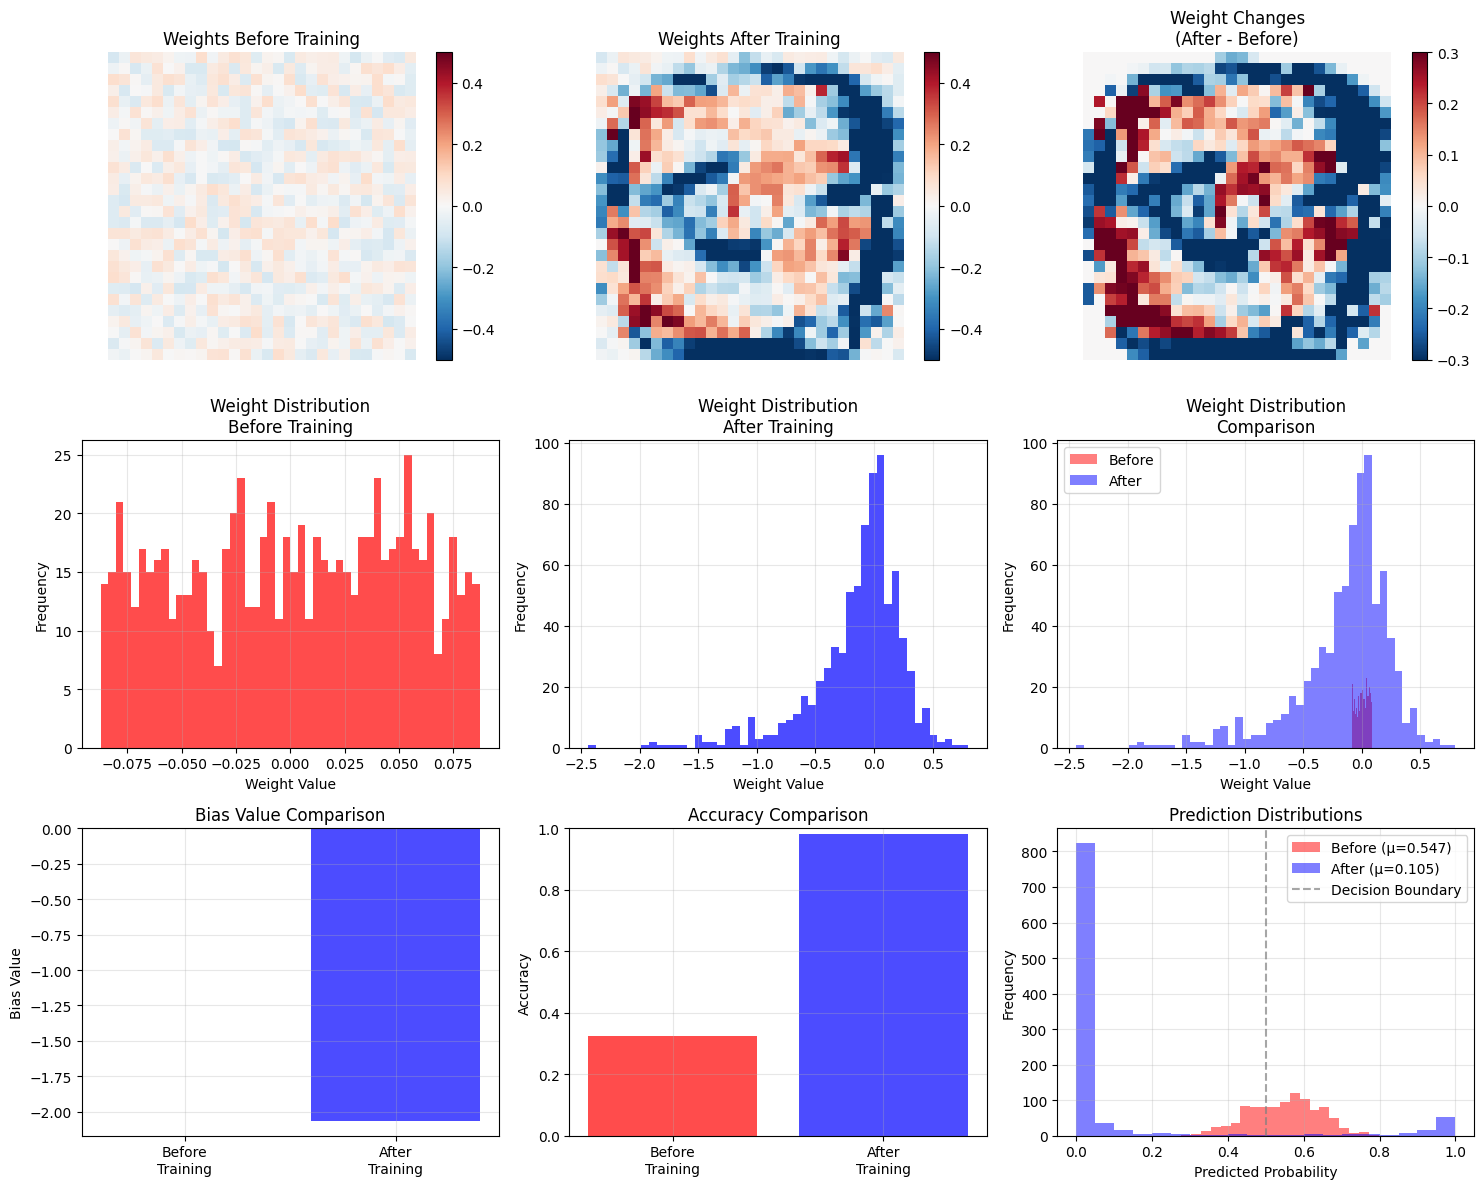

In [19]:
# Visualize the changes
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

# Row 1: Weight comparisons
weights_before_img = initial_weights.reshape(28, 28)
weights_after_img = trained_weights.reshape(28, 28)
weight_change_img = weights_after_img - weights_before_img

im1 = axes[0, 0].imshow(weights_before_img, cmap='RdBu_r', vmin=-0.5, vmax=0.5)
axes[0, 0].set_title('Weights Before Training')
axes[0, 0].axis('off')
plt.colorbar(im1, ax=axes[0, 0])

im2 = axes[0, 1].imshow(weights_after_img, cmap='RdBu_r', vmin=-0.5, vmax=0.5)
axes[0, 1].set_title('Weights After Training')
axes[0, 1].axis('off')
plt.colorbar(im2, ax=axes[0, 1])

im3 = axes[0, 2].imshow(weight_change_img, cmap='RdBu_r', vmin=-0.3, vmax=0.3)
axes[0, 2].set_title('Weight Changes\n(After - Before)')
axes[0, 2].axis('off')
plt.colorbar(im3, ax=axes[0, 2])

# Row 2: Weight distributions
axes[1, 0].hist(initial_weights.flatten(), bins=50, alpha=0.7, color='red', label='Before')
axes[1, 0].set_title('Weight Distribution\nBefore Training')
axes[1, 0].set_xlabel('Weight Value')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].hist(trained_weights.flatten(), bins=50, alpha=0.7, color='blue', label='After')
axes[1, 1].set_title('Weight Distribution\nAfter Training')
axes[1, 1].set_xlabel('Weight Value')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].grid(True, alpha=0.3)

# Overlay comparison
axes[1, 2].hist(initial_weights.flatten(), bins=50, alpha=0.5, color='red', label='Before')
axes[1, 2].hist(trained_weights.flatten(), bins=50, alpha=0.5, color='blue', label='After')
axes[1, 2].set_title('Weight Distribution\nComparison')
axes[1, 2].set_xlabel('Weight Value')
axes[1, 2].set_ylabel('Frequency')
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)

# Row 3: Bias comparison and prediction comparison
bias_comparison = [initial_biases[0], trained_biases[0]]
bias_labels = ['Before\nTraining', 'After\nTraining']
colors = ['red', 'blue']

axes[2, 0].bar(bias_labels, bias_comparison, color=colors, alpha=0.7)
axes[2, 0].axhline(y=0, color='gray', linestyle='--', alpha=0.5)
axes[2, 0].set_title('Bias Value Comparison')
axes[2, 0].set_ylabel('Bias Value')
axes[2, 0].grid(True, alpha=0.3)

# Prediction accuracy comparison
acc_comparison = [accuracy_before, accuracy_after]
acc_labels = ['Before\nTraining', 'After\nTraining']

axes[2, 1].bar(acc_labels, acc_comparison, color=colors, alpha=0.7)
axes[2, 1].set_title('Accuracy Comparison')
axes[2, 1].set_ylabel('Accuracy')
axes[2, 1].set_ylim(0, 1)
axes[2, 1].grid(True, alpha=0.3)

# Prediction distribution comparison
axes[2, 2].hist(predictions_before.flatten(), bins=20, alpha=0.5, color='red',
                label=f'Before (μ={np.mean(predictions_before):.3f})')
axes[2, 2].hist(predictions_after.flatten(), bins=20, alpha=0.5, color='blue',
                label=f'After (μ={np.mean(predictions_after):.3f})')
axes[2, 2].axvline(x=0.5, color='gray', linestyle='--', alpha=0.7, label='Decision Boundary')
axes[2, 2].set_title('Prediction Distributions')
axes[2, 2].set_xlabel('Predicted Probability')
axes[2, 2].set_ylabel('Frequency')
axes[2, 2].legend()
axes[2, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## Step 14 — Pre/post sigmoid values after training

We rerun the by-hand calculation from Step 9 on the **same five images**, now with trained weights,
and print both results side by side.

In [20]:
# Step 14: Pre and Post Sigmoid Analysis (After Training)
# =======================================================
print("\n📊 Pre and Post Sigmoid Analysis (After Training)...")

# Compute pre-sigmoid values for the same samples after training
post_training_pre_sigmoid = []
post_training_post_sigmoid = []

for i, image in enumerate(sample_images):
    # Compute pre-sigmoid value with trained weights
    raw_output = np.dot(image, trained_weights.flatten()) + trained_biases[0]
    sigmoid_output = sigmoid(raw_output)

    post_training_pre_sigmoid.append(raw_output)
    post_training_post_sigmoid.append(sigmoid_output)

    actual_label = y_sample[i]

    print(f"Sample {i+1}:")
    print(f"  Before training: Pre-sigmoid={pre_sigmoid_values[i]:6.3f} → Post-sigmoid={post_sigmoid_values[i]:.3f}")
    print(f"  After training:  Pre-sigmoid={raw_output:6.3f} → Post-sigmoid={sigmoid_output:.3f}")
    print(f"  Actual label: {actual_label}, Change in confidence: {abs(sigmoid_output - 0.5) - abs(post_sigmoid_values[i] - 0.5):+.3f}")
    print()


📊 Pre and Post Sigmoid Analysis (After Training)...
Sample 1:
  Before training: Pre-sigmoid= 0.361 → Post-sigmoid=0.589
  After training:  Pre-sigmoid=-5.898 → Post-sigmoid=0.003
  Actual label: 0, Change in confidence: +0.408

Sample 2:
  Before training: Pre-sigmoid=-0.098 → Post-sigmoid=0.476
  After training:  Pre-sigmoid=-6.098 → Post-sigmoid=0.002
  Actual label: 0, Change in confidence: +0.473

Sample 3:
  Before training: Pre-sigmoid= 0.354 → Post-sigmoid=0.588
  After training:  Pre-sigmoid=-7.304 → Post-sigmoid=0.001
  Actual label: 0, Change in confidence: +0.412

Sample 4:
  Before training: Pre-sigmoid=-0.282 → Post-sigmoid=0.430
  After training:  Pre-sigmoid=-12.356 → Post-sigmoid=0.000
  Actual label: 0, Change in confidence: +0.430

Sample 5:
  Before training: Pre-sigmoid= 0.299 → Post-sigmoid=0.574
  After training:  Pre-sigmoid=-14.216 → Post-sigmoid=0.000
  Actual label: 0, Change in confidence: +0.426



### Before vs after, on the sigmoid curve

Green points are real 3s, red points are not.

> **Look for:** on the left the points cluster near the middle; on the right they have been pushed
> out to the flat ends of the curve. Training did not change the sigmoid — it changed the numbers
> we feed into it.

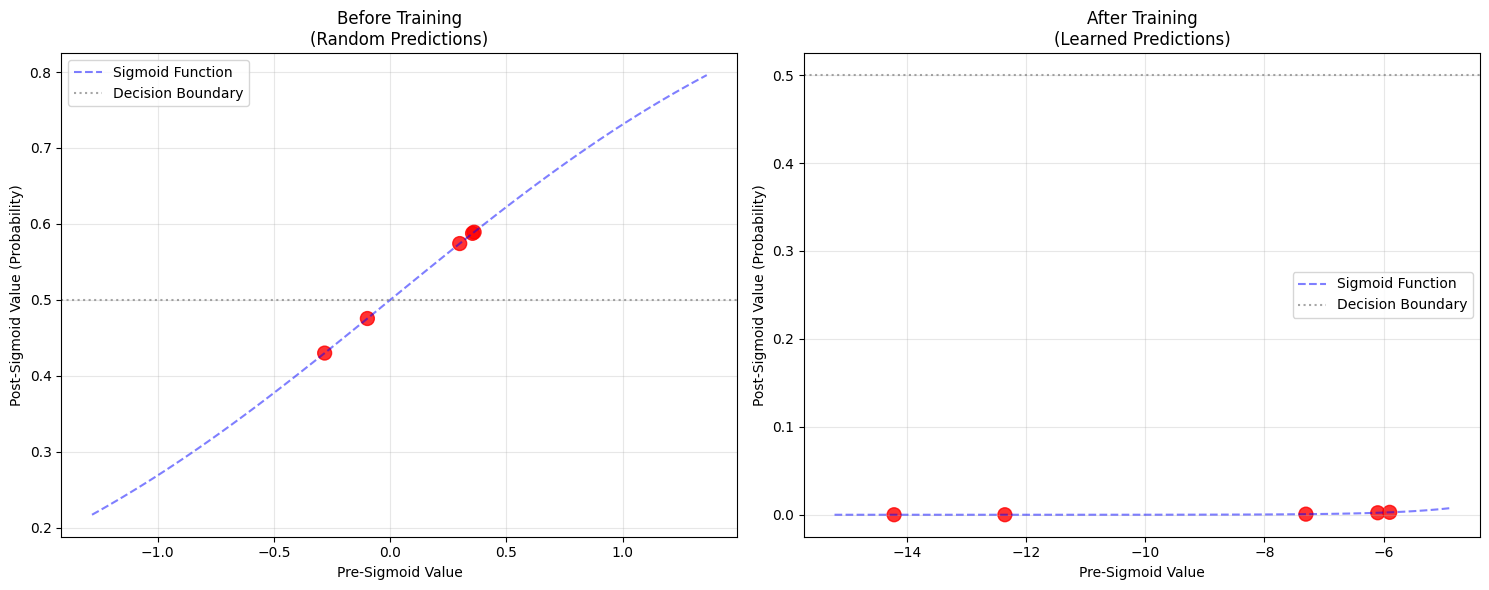

In [21]:
# Visualize sigmoid transformation before and after
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Before training
colors_before = ['red' if y_sample[i] == 0 else 'green' for i in range(5)]
ax1.scatter(pre_sigmoid_values, post_sigmoid_values, c=colors_before, s=100, alpha=0.8)
x_range1 = np.linspace(min(pre_sigmoid_values)-1, max(pre_sigmoid_values)+1, 100)
y_sigmoid1 = sigmoid(x_range1)
ax1.plot(x_range1, y_sigmoid1, 'b--', alpha=0.5, label='Sigmoid Function')
ax1.axhline(y=0.5, color='gray', linestyle=':', alpha=0.7, label='Decision Boundary')
ax1.set_xlabel('Pre-Sigmoid Value')
ax1.set_ylabel('Post-Sigmoid Value (Probability)')
ax1.set_title('Before Training\n(Random Predictions)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# After training
colors_after = ['red' if y_sample[i] == 0 else 'green' for i in range(5)]
ax2.scatter(post_training_pre_sigmoid, post_training_post_sigmoid, c=colors_after, s=100, alpha=0.8)
x_range2 = np.linspace(min(post_training_pre_sigmoid)-1, max(post_training_pre_sigmoid)+1, 100)
y_sigmoid2 = sigmoid(x_range2)
ax2.plot(x_range2, y_sigmoid2, 'b--', alpha=0.5, label='Sigmoid Function')
ax2.axhline(y=0.5, color='gray', linestyle=':', alpha=0.7, label='Decision Boundary')
ax2.set_xlabel('Pre-Sigmoid Value')
ax2.set_ylabel('Post-Sigmoid Value (Probability)')
ax2.set_title('After Training\n(Learned Predictions)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Key observations

In [22]:
print("🔍 Key Observations:")
print(f"1. Bias changed from {initial_biases[0]:.3f} to {trained_biases[0]:.3f}")
print(f"2. Pre-sigmoid values became more extreme (further from 0)")
print(f"3. Post-sigmoid values became more confident (closer to 0 or 1)")
print(f"4. The network learned to separate digit 3 from other digits")

🔍 Key Observations:
1. Bias changed from 0.000 to -2.066
2. Pre-sigmoid values became more extreme (further from 0)
3. Post-sigmoid values became more confident (closer to 0 or 1)
4. The network learned to separate digit 3 from other digits


---
## Step 15 — Plot the training curves

`model.fit` returned a `history` object holding the loss and accuracy for every epoch.
Plotting them is the standard way to diagnose training.

> **Look for:**
> - both loss curves falling and flattening out → training worked
> - validation loss turning back *up* while training loss keeps falling → overfitting
> - curves still falling steeply at epoch 10 → more epochs might help


📊 Visualizing training progress...


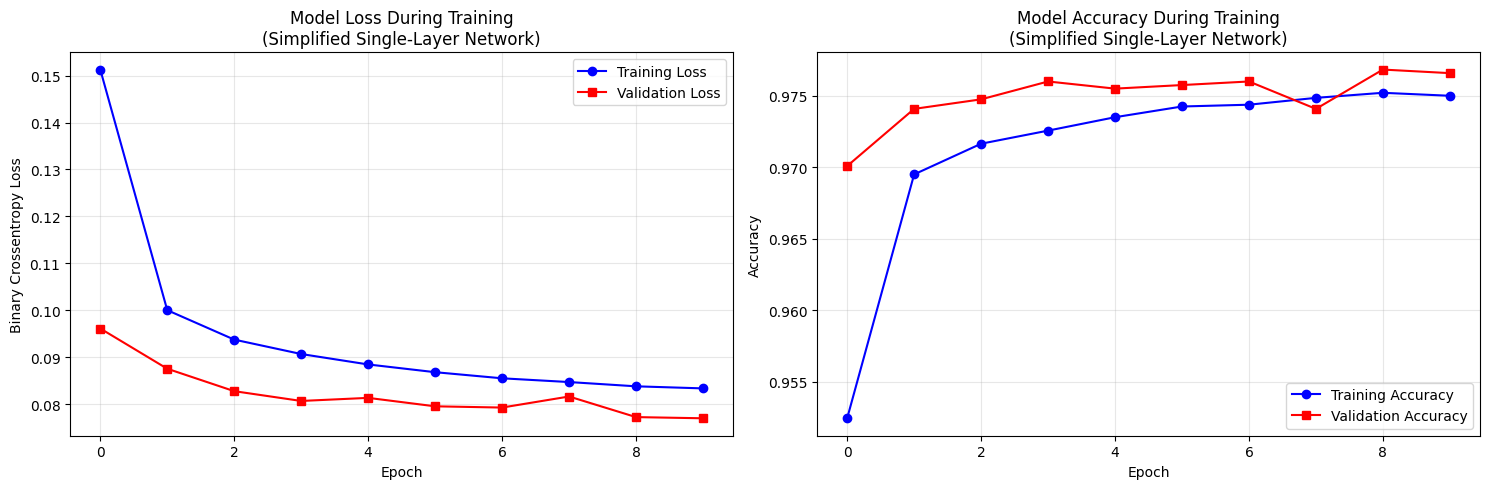

Final training accuracy: 0.9750
Final validation accuracy: 0.9766
Notice: Even with just one layer, we can achieve good results!


In [23]:
# Step 15: Visualize Training Progress
# ===================================
print("\n📊 Visualizing training progress...")

# Plot training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot loss over epochs
ax1.plot(history.history['loss'], 'b-', label='Training Loss', marker='o')
ax1.plot(history.history['val_loss'], 'r-', label='Validation Loss', marker='s')
ax1.set_title('Model Loss During Training\n(Simplified Single-Layer Network)')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Binary Crossentropy Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot accuracy over epochs
ax2.plot(history.history['accuracy'], 'b-', label='Training Accuracy', marker='o')
ax2.plot(history.history['val_accuracy'], 'r-', label='Validation Accuracy', marker='s')
ax2.set_title('Model Accuracy During Training\n(Simplified Single-Layer Network)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Final training accuracy: {history.history['accuracy'][-1]:.4f}")
print(f"Final validation accuracy: {history.history['val_accuracy'][-1]:.4f}")
print("Notice: Even with just one layer, we can achieve good results!")

---
## Step 16 — Test the trained model

The honest score: performance on the 10,000 test images the network has **never seen**.

> **Remember Step 4:** roughly 90% of test images are not 3s, so an "always say no" model scores 90%.
> Our number needs to be meaningfully above that to be impressive.

In [24]:
# Step 16: Test the Trained Model
# ==============================
print("\n🎯 Testing the trained model...")

# Evaluate on test set
test_loss, test_accuracy = model.evaluate(x_test_processed, y_test_binary, verbose=0)

print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Test Loss: {test_loss:.4f}")
baseline = 1 - y_test_binary.mean()
print(f"Yardstick: always answering 'not a 3' scores {baseline*100:.2f}% on this test set")
print(f"A single-layer network achieved {test_accuracy*100:.1f}%, {(test_accuracy - baseline)*100:.1f} points above that yardstick")

# Make predictions on full test set
all_predictions = model.predict(x_test_processed, verbose=0)

print(f"\nPrediction format:")
print(f"  Raw predictions are probabilities between 0 and 1")
print(f"  Example predictions: {all_predictions[:5].flatten()}")

# Convert probabilities to binary predictions (threshold = 0.5)
all_predicted_classes = (all_predictions > 0.5).astype(int)

print(f"  Binary predictions: {all_predicted_classes[:5].flatten()}")
print(f"  Actual labels:      {y_test_binary[:5]}")


🎯 Testing the trained model...


Test Accuracy: 0.9782 (97.82%)
Test Loss: 0.0731
Yardstick: always answering 'not a 3' scores 89.90% on this test set
A single-layer network achieved 97.8%, 7.9 points above that yardstick



Prediction format:
  Raw predictions are probabilities between 0 and 1
  Example predictions: [3.31255384e-02 2.11708044e-04 1.26936305e-02 1.03681828e-04
 3.76696262e-05]
  Binary predictions: [0 0 0 0 0]
  Actual labels:      [0 0 0 0 0]


---
## Step 17 — Analyse the predictions

Accuracy is a single number and hides a lot. Here we split the test set into correct vs incorrect,
and confident vs unsure (probability near 0/1 versus stuck in the middle).

In [25]:
# Step 17: Analyze Model Predictions
# =================================
print("\n🔍 Analyzing model predictions...")

# Find some correct and incorrect predictions
correct_mask = (all_predicted_classes.flatten() == y_test_binary)
incorrect_mask = ~correct_mask

correct_indices = np.where(correct_mask)[0]
incorrect_indices = np.where(incorrect_mask)[0]

print(f"Correct predictions: {np.sum(correct_mask)}/{len(y_test_binary)} ({np.mean(correct_mask)*100:.1f}%)")
print(f"Incorrect predictions: {np.sum(incorrect_mask)}/{len(y_test_binary)} ({np.mean(incorrect_mask)*100:.1f}%)")

# Analyze prediction confidence
high_confidence_correct = np.where((correct_mask) &
                                   ((all_predictions.flatten() > 0.9) |
                                    (all_predictions.flatten() < 0.1)))[0]
low_confidence_correct = np.where((correct_mask) &
                                  (all_predictions.flatten() >= 0.1) &
                                  (all_predictions.flatten() <= 0.9))[0]

print(f"High confidence correct: {len(high_confidence_correct)} (prob > 0.9 or < 0.1)")
print(f"Low confidence correct: {len(low_confidence_correct)} (prob between 0.1-0.9)")


🔍 Analyzing model predictions...
Correct predictions: 9782/10000 (97.8%)
Incorrect predictions: 218/10000 (2.2%)
High confidence correct: 9041 (prob > 0.9 or < 0.1)
Low confidence correct: 741 (prob between 0.1-0.9)


### See the actual images

Four rows: correct predictions, incorrect predictions, confident 3s, and confident non-3s.
Titles read `A:` actual digit, `P:` predicted class, and the probability in brackets.

> **Look for:** the mistakes in row 2. Are they sloppy 3s? Or 5s, 8s and 2s that share strokes
> with a 3? That tells you *why* a single-layer model struggles.

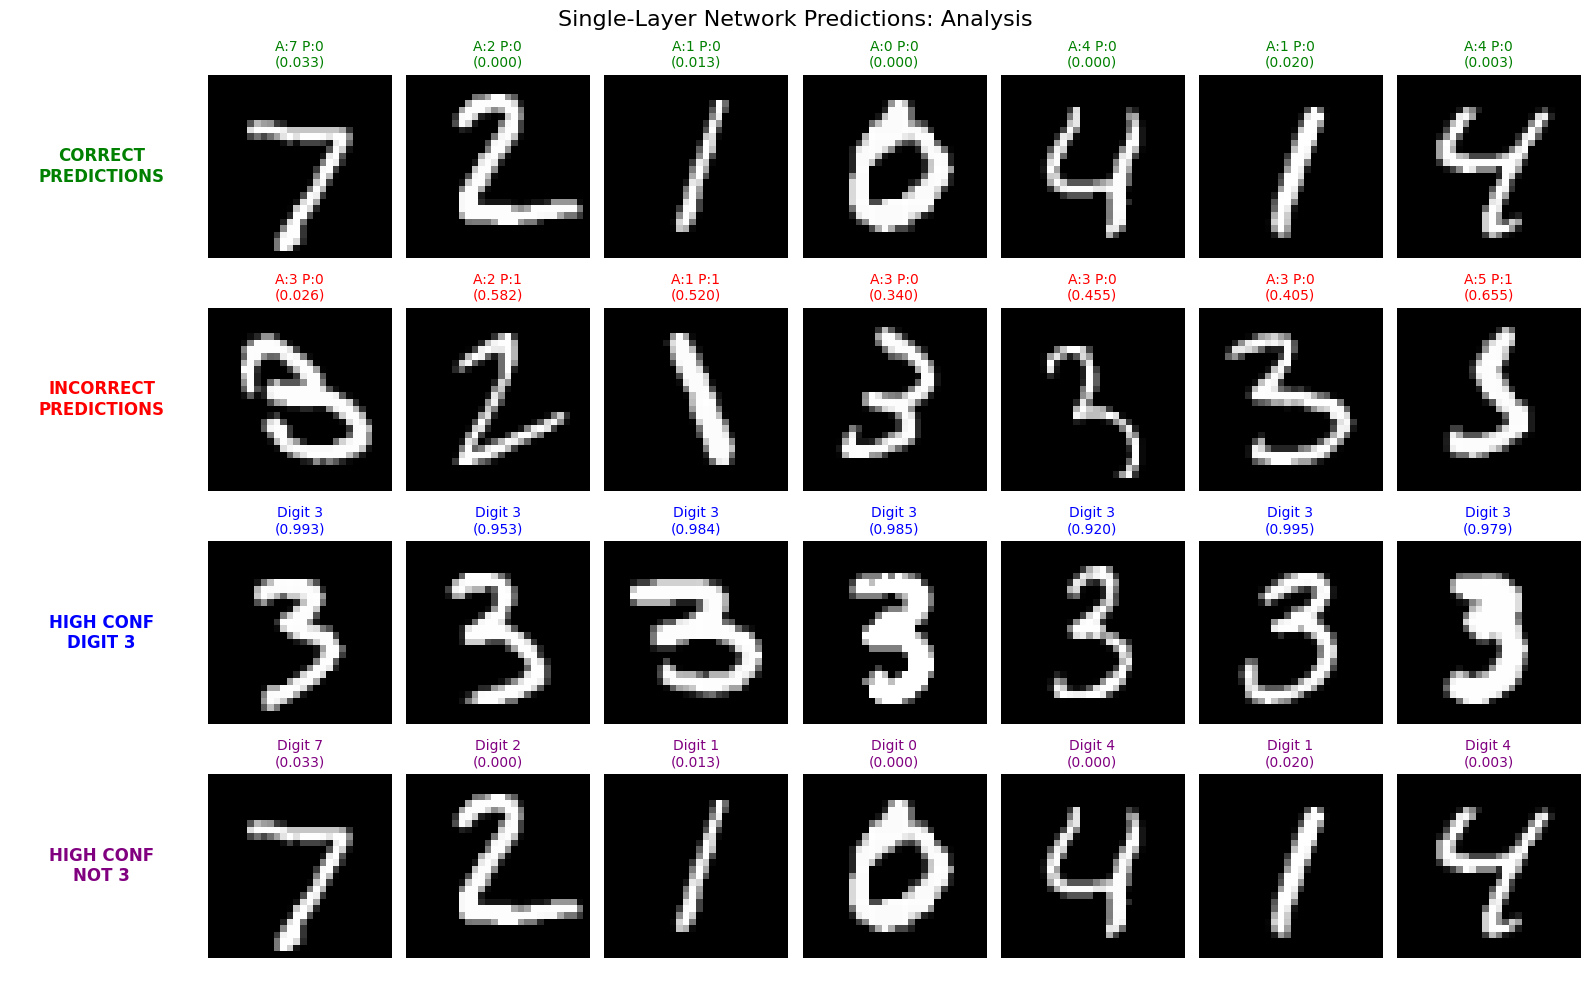

In [26]:
# Visualize some predictions
fig, axes = plt.subplots(4, 8, figsize=(16, 10))
fig.suptitle('Single-Layer Network Predictions: Analysis', fontsize=16)

# Show correct predictions (first row)
axes[0, 0].text(0.5, 0.5, 'CORRECT\nPREDICTIONS', ha='center', va='center',
                transform=axes[0, 0].transAxes, fontsize=12, weight='bold', color='green')
axes[0, 0].axis('off')
for i in range(7):
    if i < len(correct_indices):
        idx = correct_indices[i]
        axes[0, i+1].imshow(x_test[idx], cmap='gray')
        prob = all_predictions[idx][0]
        actual = y_test[idx]
        predicted = all_predicted_classes[idx][0]
        axes[0, i+1].set_title(f'A:{actual} P:{predicted}\n({prob:.3f})',
                               color='green', fontsize=10)
        axes[0, i+1].axis('off')

# Show incorrect predictions (second row)
axes[1, 0].text(0.5, 0.5, 'INCORRECT\nPREDICTIONS', ha='center', va='center',
                transform=axes[1, 0].transAxes, fontsize=12, weight='bold', color='red')
axes[1, 0].axis('off')
for i in range(7):
    if i < len(incorrect_indices):
        idx = incorrect_indices[i]
        axes[1, i+1].imshow(x_test[idx], cmap='gray')
        prob = all_predictions[idx][0]
        actual = y_test[idx]
        predicted = all_predicted_classes[idx][0]
        axes[1, i+1].set_title(f'A:{actual} P:{predicted}\n({prob:.3f})',
                               color='red', fontsize=10)
        axes[1, i+1].axis('off')

# Show high confidence digit 3 predictions (third row)
digit_3_high_conf = np.where((y_test_binary == 1) & (all_predictions.flatten() > 0.9))[0]
axes[2, 0].text(0.5, 0.5, 'HIGH CONF\nDIGIT 3', ha='center', va='center',
                transform=axes[2, 0].transAxes, fontsize=12, weight='bold', color='blue')
axes[2, 0].axis('off')
for i in range(7):
    if i < len(digit_3_high_conf):
        idx = digit_3_high_conf[i]
        axes[2, i+1].imshow(x_test[idx], cmap='gray')
        prob = all_predictions[idx][0]
        axes[2, i+1].set_title(f'Digit 3\n({prob:.3f})',
                               color='blue', fontsize=10)
        axes[2, i+1].axis('off')

# Show high confidence NOT digit 3 predictions (fourth row)
not_digit_3_high_conf = np.where((y_test_binary == 0) & (all_predictions.flatten() < 0.1))[0]
axes[3, 0].text(0.5, 0.5, 'HIGH CONF\nNOT 3', ha='center', va='center',
                transform=axes[3, 0].transAxes, fontsize=12, weight='bold', color='purple')
axes[3, 0].axis('off')
for i in range(7):
    if i < len(not_digit_3_high_conf):
        idx = not_digit_3_high_conf[i]
        axes[3, i+1].imshow(x_test[idx], cmap='gray')
        prob = all_predictions[idx][0]
        actual_digit = y_test[idx]
        axes[3, i+1].set_title(f'Digit {actual_digit}\n({prob:.3f})',
                               color='purple', fontsize=10)
        axes[3, i+1].axis('off')

plt.tight_layout()
plt.show()

---
## Step 18 — What did the weights actually learn?

Grab the final weights so we can dissect them.

In [27]:
# Step 18: Examine Learned Weights Pattern
# ========================================
print("\n🔍 Examining what the single-layer network learned...")

# The weights now represent what the network considers important for detecting digit 3
final_weights, final_biases = model.layers[0].get_weights()


🔍 Examining what the single-layer network learned...


### The learned weight pattern, next to real 3s

We compare the weight image with real training 3s and with the *average* 3.

- **Positive (red) weights** — "bright here ⇒ more likely a 3"
- **Negative (blue) weights** — "bright here ⇒ less likely a 3"

> **Look for:** the positive weights roughly trace where 3s have ink; the negative weights sit
> where *other* digits have ink but 3s don't — for example the left-hand vertical stroke that
> would close the loops into an 8.

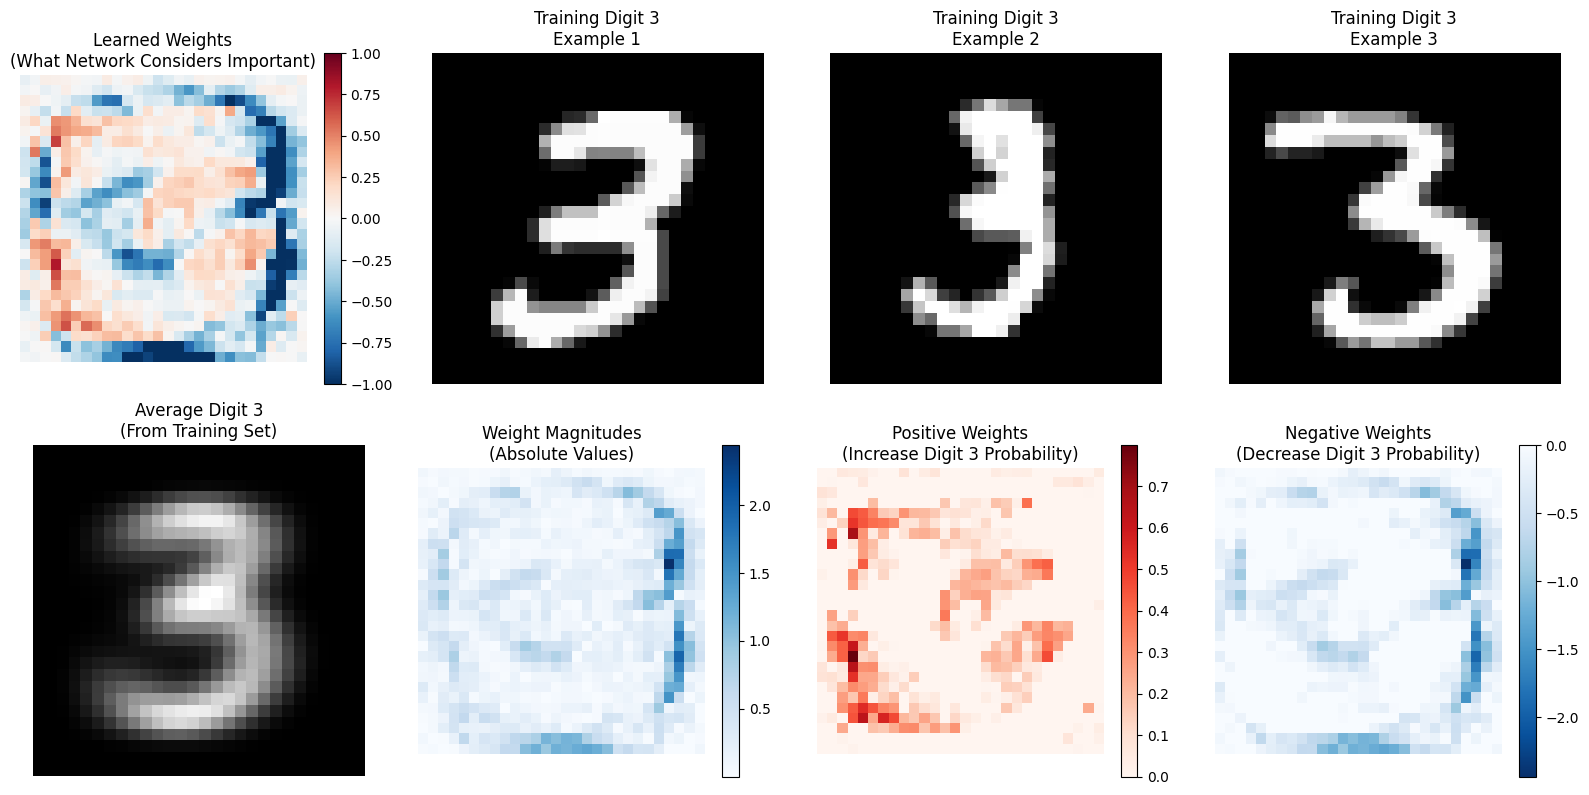

In [28]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

# Show learned weights
weights_image = final_weights.reshape(28, 28)
im1 = axes[0, 0].imshow(weights_image, cmap='RdBu_r', vmin=-1, vmax=1)
axes[0, 0].set_title('Learned Weights\n(What Network Considers Important)')
axes[0, 0].axis('off')
plt.colorbar(im1, ax=axes[0, 0])

# Show some example digit 3s from training set
digit_3_examples = x_train[y_train == 3][:3]
for i, example in enumerate(digit_3_examples):
    axes[0, i+1].imshow(example, cmap='gray')
    axes[0, i+1].set_title(f'Training Digit 3\nExample {i+1}')
    axes[0, i+1].axis('off')

# Show average digit 3
avg_digit_3 = np.mean(x_train[y_train == 3], axis=0)
axes[1, 0].imshow(avg_digit_3, cmap='gray')
axes[1, 0].set_title('Average Digit 3\n(From Training Set)')
axes[1, 0].axis('off')

# Show weight magnitudes (absolute values)
weight_magnitudes = np.abs(weights_image)
im2 = axes[1, 1].imshow(weight_magnitudes, cmap='Blues')
axes[1, 1].set_title('Weight Magnitudes\n(Absolute Values)')
axes[1, 1].axis('off')
plt.colorbar(im2, ax=axes[1, 1])

# Show positive weights (what increases digit 3 probability)
positive_weights = np.maximum(weights_image, 0)
im3 = axes[1, 2].imshow(positive_weights, cmap='Reds')
axes[1, 2].set_title('Positive Weights\n(Increase Digit 3 Probability)')
axes[1, 2].axis('off')
plt.colorbar(im3, ax=axes[1, 2])

# Show negative weights (what decreases digit 3 probability)
negative_weights = np.minimum(weights_image, 0)
im4 = axes[1, 3].imshow(negative_weights, cmap='Blues_r')
axes[1, 3].set_title('Negative Weights\n(Decrease Digit 3 Probability)')
axes[1, 3].axis('off')
plt.colorbar(im4, ax=axes[1, 3])

plt.tight_layout()
plt.show()

### Weight statistics

In [29]:
print(f"📊 Weight Analysis:")
print(f"  Final bias: {final_biases[0]:.4f}")
print(f"  Weight range: {final_weights.min():.4f} to {final_weights.max():.4f}")
print(f"  Most positive weight: {final_weights.max():.4f} (strong digit 3 indicator)")
print(f"  Most negative weight: {final_weights.min():.4f} (strong non-digit 3 indicator)")

📊 Weight Analysis:
  Final bias: -2.0655
  Weight range: -2.4384 to 0.7984
  Most positive weight: 0.7984 (strong digit 3 indicator)
  Most negative weight: -2.4384 (strong non-digit 3 indicator)


---
## Step 19 — Trace one prediction end to end

One test image, followed all the way through: pixels → weighted sum → bias → sigmoid → answer.
We also check our hand-computed value against `model.predict`, and split the sum into the
positive evidence and the negative evidence.

> **Look for:** step 3 and step 4 should print (almost) the same number. That confirms the network
> really is doing nothing more than the arithmetic in Step 9.

In [30]:
# Step 19: Interactive Prediction Example (Updated)
# =================================================
print("\n🎮 Interactive prediction example with single layer...")

# Let's manually trace through a prediction
sample_idx = 42  # Pick a sample
sample_image = x_test_processed[sample_idx]
actual_label = y_test_binary[sample_idx]

print(f"Tracing prediction for test sample {sample_idx}:")
print(f"Actual label: {actual_label} ({'Digit 3' if actual_label == 1 else 'Not digit 3'})")

print(f"\n1. Input: 784 pixel values (showing first 10): {sample_image[:10]}")

# Single layer computation
raw_output = np.dot(sample_image, final_weights.flatten()) + final_biases[0]
final_output = sigmoid(raw_output)

print(f"2. Raw output (before sigmoid): {raw_output:.4f}")
print(f"3. Final prediction (after sigmoid): {final_output:.4f}")

# Compare with model prediction
model_prediction = model.predict(sample_image.reshape(1, -1), verbose=0)[0][0]
print(f"4. Model prediction (should match): {model_prediction:.4f}")

# Break down the computation
positive_contribution = np.sum(sample_image * np.maximum(final_weights.flatten(), 0))
negative_contribution = np.sum(sample_image * np.minimum(final_weights.flatten(), 0))
bias_contribution = final_biases[0]

print(f"\n🔍 Detailed breakdown:")
print(f"  Positive contribution: {positive_contribution:.4f}")
print(f"  Negative contribution: {negative_contribution:.4f}")
print(f"  Bias contribution: {bias_contribution:.4f}")
print(f"  Total (pre-sigmoid): {positive_contribution + negative_contribution + bias_contribution:.4f}")


🎮 Interactive prediction example with single layer...
Tracing prediction for test sample 42:
Actual label: 0 (Not digit 3)

1. Input: 784 pixel values (showing first 10): [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
2. Raw output (before sigmoid): -7.1506
3. Final prediction (after sigmoid): 0.0008
4. Model prediction (should match): 0.0008

🔍 Detailed breakdown:
  Positive contribution: 5.2864
  Negative contribution: -10.3715
  Bias contribution: -2.0655
  Total (pre-sigmoid): -7.1506


### Visualise that single decision

The middle panel is `pixel × weight` for every pixel — literally a map of which parts of *this*
image argued for a 3 (red) and which argued against (blue).

> **Try it:** change `sample_idx` in the cell above to any number from 0 to 9999 and rerun both
> cells. Find an image the model gets wrong and look at where its evidence went.

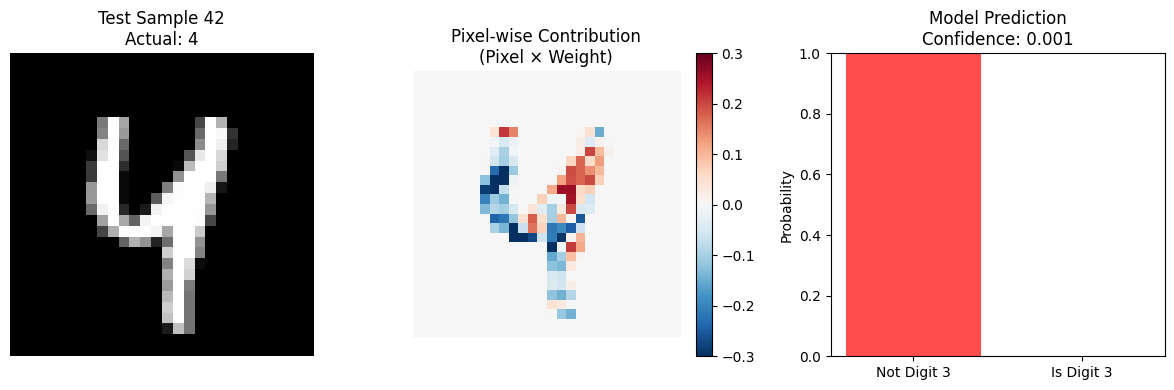

In [31]:
# Visualize this sample with weight overlay
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(x_test[sample_idx], cmap='gray')
plt.title(f'Test Sample {sample_idx}\nActual: {y_test[sample_idx]}')
plt.axis('off')

plt.subplot(1, 3, 2)
# Show pixel-wise contribution (pixel value * weight)
contribution = sample_image.reshape(28, 28) * weights_image
plt.imshow(contribution, cmap='RdBu_r', vmin=-0.3, vmax=0.3)
plt.title('Pixel-wise Contribution\n(Pixel × Weight)')
plt.axis('off')
plt.colorbar()

plt.subplot(1, 3, 3)
plt.bar(['Not Digit 3', 'Is Digit 3'], [1-final_output, final_output],
        color=['red', 'green'], alpha=0.7)
plt.title(f'Model Prediction\nConfidence: {final_output:.3f}')
plt.ylabel('Probability')
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

---
## Step 20 — Summary and key learnings

In [32]:
# Step 20: Summary and Key Learnings
# =================================
print("\n🎓 KEY LEARNINGS SUMMARY")
print("=" * 60)

print("\n1. 📊 SIMPLIFIED ARCHITECTURE:")
print(f"   • Single layer: 784 inputs → 1 output")
print(f"   • Only {model.count_params():,} parameters (much simpler!)")
print(f"   • Direct connection from pixels to prediction")
print(f"   • Achieved {test_accuracy*100:.2f}% accuracy")

print("\n2. ⚖️ WEIGHTS AND BIASES EVOLUTION:")
print(f"   • Bias changed: {initial_biases[0]:.6f} → {final_biases[0]:.6f}")
print(f"   • Weights learned pixel importance for digit 3")
print(f"   • Positive weights: pixels that indicate digit 3")
print(f"   • Negative weights: pixels that contradict digit 3")

print("\n3. 📈 SIGMOID FUNCTION BEHAVIOR:")
print(f"   • Before training: predictions near 0.5 (uncertain)")
print(f"   • After training: predictions near 0 or 1 (confident)")
print(f"   • Pre-sigmoid values became more extreme")
print(f"   • Sigmoid maps extreme values to confident probabilities")

print("\n4. 🎯 BINARY CLASSIFICATION SUCCESS:")
print(f"   • Converted 10-class to 2-class problem")
print(f"   • Single layer learned to detect digit 3 patterns")
print(f"   • Bias helps shift decision boundary")
print(f"   • Weights encode visual features of digit 3")

print("\n5. 🔬 BEFORE vs AFTER TRAINING:")
print(f"   • Accuracy: {accuracy_before*100:.1f}% (untrained, 1,000 test images) → {test_accuracy*100:.1f}% (trained, all 10,000)")
print(f"   • Predictions: random → systematic")
print(f"   • Weights: random → meaningful patterns")
print(f"   • Bias: small → optimized for digit 3 detection")

print("\n6. 🧠 WHAT THE NETWORK LEARNED:")
print(f"   • Each pixel has a 'vote' for digit 3 (weight)")
print(f"   • Positive weights: 'if this pixel is bright, it's likely digit 3'")
print(f"   • Negative weights: 'if this pixel is bright, it's likely NOT digit 3'")
print(f"   • Bias: overall tendency toward digit 3 or not")

print(f"\n🎉 Amazing Results with Minimal Complexity!")
print(f"   ✓ Built simplest possible neural network")
print(f"   ✓ Understood weight and bias evolution")
print(f"   ✓ Visualized pre/post sigmoid transformations")
print(f"   ✓ Achieved {test_accuracy*100:.1f}% accuracy with just {model.count_params():,} parameters")

print(f"\n🚀 Key Insights:")
print(f"   • Even one neuron can learn a useful pattern")
print(f"   • Weights encode visual features automatically")
print(f"   • Bias helps fine-tune decision boundaries")
print(f"   • Sigmoid creates smooth probability outputs")
print(f"   • Training transforms random weights into meaningful detectors")

print(f"\n🔬 Experiment Ideas:")
print(f"   • Try detecting other digits (0-9)")
print(f"   • Experiment with different learning rates")
print(f"   • Add more layers and compare performance")
print(f"   • Visualize weight evolution during training")
print(f"   • Test on handwritten digits you draw yourself!")

print(f"\n🎯 Congratulations! You've mastered:")
print(f"   → Neural network fundamentals")
print(f"   → Weight and bias concepts")
print(f"   → Sigmoid activation function")
print(f"   → Binary classification")
print(f"   → Training process visualization")
print(f"   → Pre/post activation analysis")
print(f"   → Single-layer network capabilities")

print("\n" + "="*60)
print("🌟 YOU'VE SUCCESSFULLY COMPLETED YOUR FIRST NEURAL NETWORK! 🌟")
print("="*60)
print(f"   • Try different network architectures (more/fewer neurons)")
print(f"   • Experiment with different activation functions")
print(f"   • Classify other digits or multiple digits at once")
print(f"   • Add more hidden layers (deep learning!)")


🎓 KEY LEARNINGS SUMMARY

1. 📊 SIMPLIFIED ARCHITECTURE:
   • Single layer: 784 inputs → 1 output
   • Only 785 parameters (much simpler!)
   • Direct connection from pixels to prediction
   • Achieved 97.82% accuracy

2. ⚖️ WEIGHTS AND BIASES EVOLUTION:
   • Bias changed: 0.000000 → -2.065521
   • Weights learned pixel importance for digit 3
   • Positive weights: pixels that indicate digit 3
   • Negative weights: pixels that contradict digit 3

3. 📈 SIGMOID FUNCTION BEHAVIOR:
   • Before training: predictions near 0.5 (uncertain)
   • After training: predictions near 0 or 1 (confident)
   • Pre-sigmoid values became more extreme
   • Sigmoid maps extreme values to confident probabilities

4. 🎯 BINARY CLASSIFICATION SUCCESS:
   • Converted 10-class to 2-class problem
   • Single layer learned to detect digit 3 patterns
   • Bias helps shift decision boundary
   • Weights encode visual features of digit 3

5. 🔬 BEFORE vs AFTER TRAINING:
   • Accuracy: 32.3% (untrained, 1,000 test image

---
## Exercises

Now make the notebook your own. For each task, copy the relevant cells into a new cell below and modify them.

1. **Detect a different digit.** In Step 4, change `y_train == 3` to another digit and rerun everything
   from Step 4 down. Which digit is easiest? Which is hardest? Why might that be?
2. **Train for longer.** Set `epochs=30` in Step 12. Does test accuracy improve, or do the
   validation curves in Step 15 start to diverge?
3. **Change the batch size.** Try `batch_size=256` and `batch_size=8`. What happens to training
   speed, and to the smoothness of the curves?
4. **Move the threshold.** In Step 16, replace `> 0.5` with `> 0.9`. Accuracy on which class
   improves, and which gets worse? (Look up *precision* and *recall*.)
5. **Add a hidden layer.** In Step 6, insert `layers.Dense(32, activation='relu')` before the
   output layer. How many parameters now? How much does accuracy improve? Can you still draw the
   weights as a 28 × 28 image — and if not, why not?
6. **Break the normalisation.** Remove the `/ 255.0` in Step 5 and retrain. Explain what you see.